In [30]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
rawdata = pd.read_csv('../academic-performance-prediction/2023YRBS.csv', 
                 sep=';',
                dtype='string')

In [32]:
# The relevant questions
questions = ['q41','q42','q43','q48','q49'
             ,'q50','q51','q52','q53','q54'
             ,'q55','q85','q26','q84','q76'
             ,'q1','q2','q3','q87']

# Filtered dataframe with our questions without NA values
df = rawdata[questions].dropna()

In [33]:
# Renaming the columns so they can be distinguished easily
df = df.rename(columns={
    'q41': 'Lifetime alcohol use',
    'q42': 'Current alcohol use',
    'q43': 'Binge drinking',
    'q48': 'Current marijuana use',
    'q49': 'Prescription pain medicine use',
    'q50': 'Cocaine use',
    'q51': 'Inhalants use',
    'q52': 'Heroin use',
    'q53': 'Methamphetamine use',
    'q54': 'Ecstacy/MDMA use',
    'q55': 'Injected illegal drugs',
    'q85': 'Sleep duration',
    'q26': 'Mental health indicators (feeling hopeless/sad)',
    'q84': 'Mental health indicators (anxiety/depression)',
    'q76': 'Physical activity',
    'q1': 'Age',
    'q2': 'Sex',
    'q3': 'Grade level',
    'q87': 'Grades past 12 months'
})

# Changing data type to integers
df = df.astype(int)

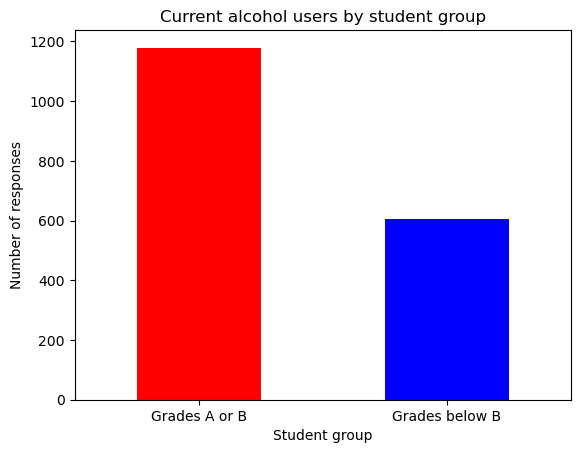

In [34]:
# Bar chart for current alcohol users by student group
alcohol = df.loc[df["Current alcohol use"] > 1].copy()
alcohol['Grades'] = alcohol["Grades past 12 months"].apply(
    lambda x: "Grades A or B" if x <= 2 else "Grades below B")

counts_alc = alcohol['Grades'].value_counts().reindex(
    ["Grades A or B", "Grades below B"],
    fill_value=0
)
counts_alc.plot(kind="bar", color=["Red", "Blue"])
plt.xlabel("Student group")
plt.ylabel("Number of responses")
plt.title("Current alcohol users by student group")
plt.xticks(rotation=0)
plt.show()

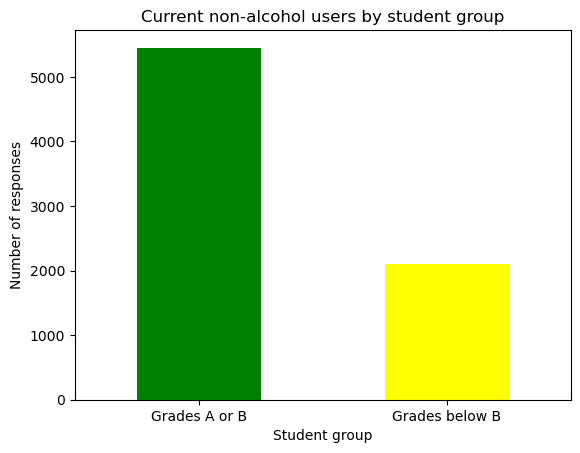

In [35]:
# Bar chart for current non-alcohol users by student group
no_alc = df.loc[df["Current alcohol use"] == 1].copy()
no_alc['Grades'] = no_alc["Grades past 12 months"].apply(
    lambda x: "Grades A or B" if x <= 2 else "Grades below B")

counts_no_alc = no_alc['Grades'].value_counts().reindex(
    ["Grades A or B", "Grades below B"],
    fill_value=0
)
counts_no_alc.plot(kind="bar", color=["Green", "Yellow"])
plt.xlabel("Student group")
plt.ylabel("Number of responses")
plt.title("Current non-alcohol users by student group")
plt.xticks(rotation=0)
plt.show()

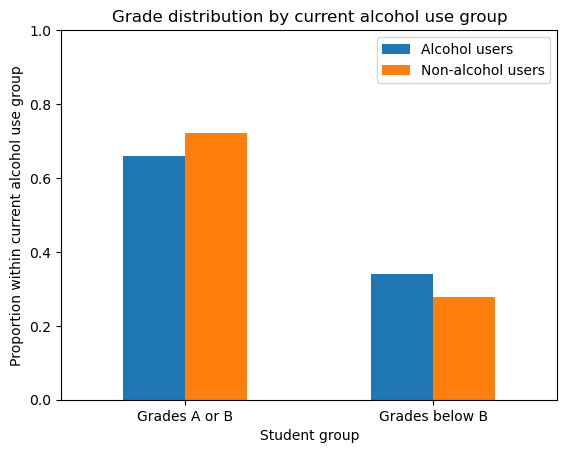

In [36]:
# Bar chart for grade distribution by current alcohol use group
combo_alc = pd.DataFrame({"Alcohol users": counts_alc, "Non-alcohol users": counts_no_alc})
prop = combo_alc.div(combo_alc.sum(axis=0), axis=1)
ax = prop.plot(kind="bar")
ax.set_title("Grade distribution by current alcohol use group")
ax.set_xlabel("Student group")
ax.set_ylabel("Proportion within current alcohol use group")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

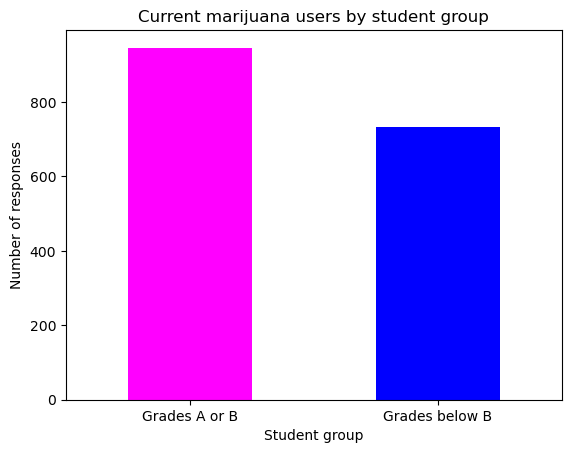

In [37]:
# Bar chart for current marijuana users by student group
mj = df.loc[df["Current marijuana use"] > 1].copy()
mj['Grades'] = mj["Grades past 12 months"].apply(
    lambda x: "Grades A or B" if x <= 2 else "Grades below B")

counts_mj = mj['Grades'].value_counts().reindex(
    ["Grades A or B", "Grades below B"],
    fill_value=0
)
counts_mj.plot(kind="bar", color=["magenta", "Blue"])
plt.xlabel("Student group")
plt.ylabel("Number of responses")
plt.title("Current marijuana users by student group")
plt.xticks(rotation=0)
plt.show()

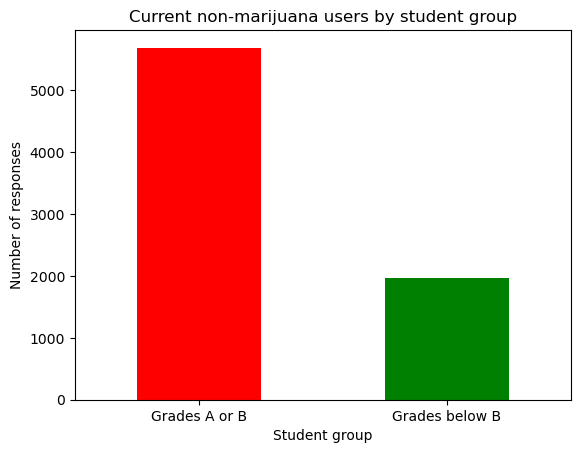

In [38]:
# Bar chart for current non-marijuana users by student group
no_mj = df.loc[df["Current marijuana use"] == 1].copy()
no_mj['Grades'] = no_mj["Grades past 12 months"].apply(
    lambda x: "Grades A or B" if x <= 2 else "Grades below B")

counts_no_mj = no_mj['Grades'].value_counts().reindex(
    ["Grades A or B", "Grades below B"],
    fill_value=0
)
counts_no_mj.plot(kind="bar", color=["Red", "Green"])
plt.xlabel("Student group")
plt.ylabel("Number of responses")
plt.title("Current non-marijuana users by student group")
plt.xticks(rotation=0)
plt.show()

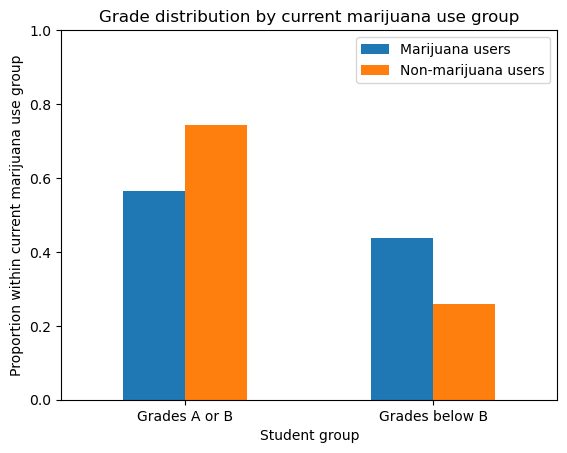

In [39]:
# Bar chart for grade distribution by current marijuana use group
combo_mj = pd.DataFrame({"Marijuana users": counts_mj, "Non-marijuana users": counts_no_mj})
prop = combo_mj.div(combo_mj.sum(axis=0), axis=1)
ax = prop.plot(kind="bar")
ax.set_title("Grade distribution by current marijuana use group")
ax.set_xlabel("Student group")
ax.set_ylabel("Proportion within current marijuana use group")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

In [28]:
import os
print("Working directory:", os.getcwd())
for root, dirs, files in os.walk('.'):
    if '2023YRBS.csv' in files:
        print("Found in:", root)

Working directory: /notebooks/academic-performance-prediction
Found in: .
